# Lab 0: Mulai dari Nol di Google Colab

**Durasi:** 30 sampai 45 menit

Lab ini membawa Anda dari nol sampai regresi pertama. Tidak perlu
pengalaman Python sebelumnya. Semua yang dibutuhkan sudah disiapkan.

Cara kerja di Colab:
1. Klik sel (kotak abu-abu berisi kode).
2. Tekan `Shift + Enter` untuk menjalankan.
3. Hasilnya muncul di bawah sel.

**Data.** Semua data ada di folder `data/`. Kalau belum ada (misalnya saat
pertama kali membuka di Colab), unggah `data_tutorial.zip` lewat panel
Files di kiri layar, lalu jalankan sel pertama di bawah sekali.



**Posisi dalam alur workshop.** Lab 0 sampai 5 mengikuti urutan Hari 1
(Sesi 1 sampai 5). Lab 6 menutup dengan data Indonesia asli.



## Cara mengikuti notebook ini

Jalankan sel berurutan dengan `Shift + Enter`. Setiap notebook dapat
dimulai sendiri setelah paket data diunggah. Sel persiapan cukup dijalankan
apa adanya; fokus latihan dimulai saat tabel data muncul.

Baca penjelasan sebelum menjalankan kode, lalu sebutkan arti hasilnya.
Ubah satu hal setiap mencoba: nama kolom pada X, pilihan model, atau nilai prediksi.
Baris `#` adalah catatan. `=` menyimpan hasil dan `==` membandingkan nilai.
Contoh `tabel["kolom"]` berarti memilih satu kolom dari tabel.

Jika muncul error merah, berhenti di sel itu dan baca baris terakhirnya.
Jika ada warning, baca pesannya dan periksa hasil estimasi sebelum lanjut.
Panduan simbol dan contoh tambahan ada di `panduan/01_panduan_pemula.md`.



### Pola pemodelan yang dipakai

`X` adalah tabel fitur dan `y` adalah kolom target. Model utama memakai
scikit-learn: buat model, jalankan `fit(X, y)`, lalu gunakan `predict(X_baru)`.
Koefisien ada pada `coef_` dan intersep pada `intercept_`. Tabel `koefisien_...`
hanya memberi nama kolom agar angka mudah dibaca. `score(X, y)` pada regresi
linear adalah R² pada data yang diberikan; hasil pada data latih belum mengukur
kemampuan memprediksi data baru.

Nama `uji_...` menandai pelengkap statistik untuk p-value, standard error, atau
uji asumsi. Perhitungannya memakai X dan y yang sama. Bagian model khusus diberi
catatan tersendiri ketika scikit-learn belum menyediakan estimatornya.



In [1]:
import os
import zipfile
from pathlib import Path

# Di komputer sendiri, temukan folder data dari lokasi notebook ini.
# Di Colab, folder kerja tetap memakai lokasi unggahan Anda.
if not Path("data").is_dir() and Path("../../data").is_dir():
    os.chdir("../..")

# Jalankan apa adanya. Paket dibuka jika alat bantu belum tersedia.
# Jika data sudah siap, menjalankan ulang sel ini tidak menimpa CSV.
if (
    Path("data_tutorial.zip").exists()
    and not Path("alat_bantu/metode_lanjutan.py").exists()
):
    with zipfile.ZipFile("data_tutorial.zip") as paket:
        paket.extractall(".")

if not Path("data/uts_2.csv").exists():
    raise FileNotFoundError(
        "Unggah data_tutorial.zip lewat panel Files di kiri Colab, "
        "lalu jalankan sel ini lagi."
    )

print("Data siap. Lanjutkan ke sel berikutnya.")



Data siap. Lanjutkan ke sel berikutnya.


## 1. Senjata yang dipakai

Lima baris impor di bawah ini muncul di hampir semua analisis:
pandas untuk tabel, numpy untuk angka, statsmodels untuk regresi,
matplotlib dan seaborn untuk grafik.



In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 11})



## 2. Baca data pertama

Satu baris perintah: `pd.read_csv("data/uts_2.csv")`. Fungsi `head()`
menampilkan 5 baris pertama supaya kita tahu isinya.



<!-- kamus_variabel:uts_2.csv -->

### Kenali data: Harga saham perusahaan

**Data:** `data/uts_2.csv`. **Satu baris:** satu perusahaan pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Harga_Saham` | Harga satu lembar saham perusahaan. | Uang per lembar; skala mata uang tidak dirinci | Y: target |
| `X1_Pendapatan_per_Saham` | EPS (Earnings Per Share): laba per lembar saham; bukan total omzet perusahaan. | Uang per lembar; skala mata uang tidak dirinci | X: penjelas |
| `X2_Rasio_Utang_Ekuitas` | DER (Debt to Equity Ratio): total utang dibagi ekuitas perusahaan. | Rasio; 1,5 berarti utang 1,5 kali ekuitas (150%) | X: penjelas |
| `X3_Belanja_Iklan` | Jumlah pengeluaran perusahaan untuk iklan. | Uang; skala dan periode belanja tidak dirinci | X: penjelas |

Nama harga, eps, der, dan iklan adalah nama singkat dari kolom di atas. Contoh DER tidak dibaca sebagai 1,5 persen.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).



In [3]:
saham = pd.read_csv("data/uts_2.csv")
saham.head()



,Y_Harga_Saham,X1_Pendapatan_per_Saham,X2_Rasio_Utang_Ekuitas,X3_Belanja_Iklan
0,255.2,15.5,1.2,55.1
1,180.9,8.2,2.1,30.8
2,350.1,25.1,0.8,80.5
3,410.5,30.8,0.5,95.2
4,155.3,6.5,2.4,25.3


## 3. Grafik pertama

Selalu lihat data sebelum menghitung. Kita pakai scatter plot sederhana.



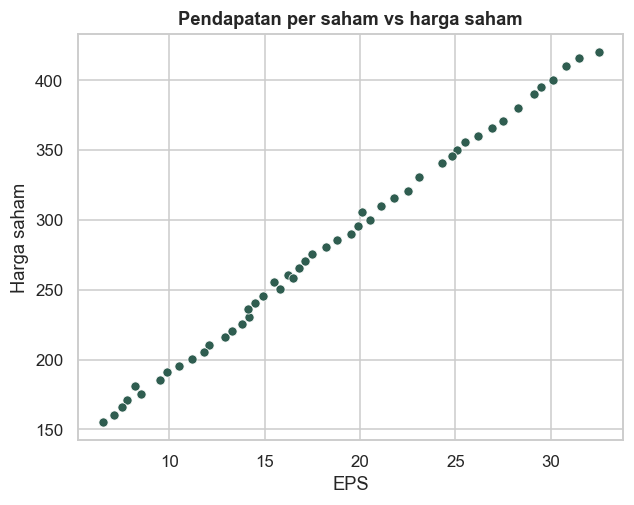

In [4]:
sns.scatterplot(data=saham, x="X1_Pendapatan_per_Saham", y="Y_Harga_Saham")
plt.title("Pendapatan per saham vs harga saham")
plt.xlabel("EPS")
plt.ylabel("Harga saham")
plt.show()



## 4. Regresi pertama

Rumus regresi ditulis `y ~ x`. Bagian kiri tilde adalah variabel yang
dijelaskan, bagian kanan adalah penjelasnya. `fit()` yang menaksir model.

Pertanyaan: apakah EPS berhubungan dengan harga saham?



In [5]:
sampel_model = saham[["Y_Harga_Saham", "X1_Pendapatan_per_Saham"]].dropna()
X_model = sampel_model[["X1_Pendapatan_per_Saham"]]
y_model = sampel_model["Y_Harga_Saham"]

model = LinearRegression()
model.fit(X_model, y_model)

koefisien_model = pd.Series(model.coef_, index=X_model.columns)
koefisien_model.loc["Intercept"] = model.intercept_

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()
print(uji_model.summary())



                            OLS Regression Results                            
Dep. Variable:          Y_Harga_Saham   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.487e+04
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           7.85e-67
Time:                        15:27:01   Log-Likelihood:                -131.31
No. Observations:                  50   AIC:                             266.6
Df Residuals:                      48   BIC:                             270.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

Tiga angka yang dibaca:

- `coef` baris pertama: intersep, nilai Y kalau X = 0.
- `coef` baris kedua: kemiringan, perubahan Y per satu unit X.
- `P>|t|` baris kedua: kalau di bawah 0,05, hubungannya signifikan.

**Cara membaca hasilnya:** kenaikan EPS satu unit diiringi kenaikan harga
saham sekitar 10,4 unit, dan hubungan itu signifikan (p-value jauh di
bawah 0,05).



In [6]:
print("Koefisien:")
print(koefisien_model.round(3))
print()
print("R-squared:", round(model.score(X_model, y_model), 3))



Koefisien:
X1_Pendapatan_per_Saham    10.410
Intercept                  87.847
dtype: float64

R-squared: 0.998


### Coba sendiri (5 menit)

Pakai `model` yang sudah jadi. Prediksi harga saham untuk EPS = 25.

Tulis di sel di bawah, baru buka jawabannya.



In [7]:
# Tulis kode Anda di sini



<details><summary>Lihat jawaban</summary>

`model.predict(pd.DataFrame({"X1_Pendapatan_per_Saham": [25]}))`
menghasilkan sekitar 348,1.

</details>



## 5. Latihan

1. Baca `data/uts_4.csv` ke variabel `harapan_hidup`. Tampilkan 5 baris
   pertama.
2. Hitung rata-rata kolom `Y_Angka_Harapan_Hidup` dan `X2_Tingkat_Imunisasi`
   dengan `.mean()`.
3. Jalankan regresi `Y_Angka_Harapan_Hidup ~ X1_Pengeluaran_Kesehatan`.
   Apakah koefisiennya signifikan?



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).



In [8]:
# Tulis jawaban Anda di sini.
# harapan_hidup = pd.read_csv(...)
# harapan_hidup.head()
# ...



## Praktik pendampingan AI

Setelah contoh regresi berjalan, salin satu sel dan minta AI:

> Saya baru belajar coding. Jelaskan kode ini satu baris setiap kali
> dalam bahasa Indonesia. Sebutkan masukannya, hasil yang disimpan,
> serta bagian yang boleh saya ubah. Gunakan nama yang sama dan
> jangan menambahkan fungsi buatan sendiri atau perulangan.

Cocokkan penjelasannya dengan tabel data dan hasil kode yang dijalankan.
AI tidak perlu menebak koefisien. Ganti satu nilai prediksi, jalankan ulang,
lalu tulis kesimpulan sendiri dengan satuan yang benar. Contoh prompt
untuk membaca output dan memahami error ada di panduan/02_panduan_ai.md.



### Selanjutnya

Selanjutnya: Lab 1, regresi linear lengkap.
